# Expecting the World

*The Mathematics of Machine Intelligence · Chapter 4*

Send only what a shared guess missed, weigh the guess against the senses, and see where surprise stops being information.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what the guess is, how reliable it has been compared with the new reading, and whether the world is steady or changing. Use the residual when a sender and receiver share a guess, the settling rule to weigh an expectation against an input, a learning-rate comparison when the question is how far to move a forecast, and the surprise-versus-information card before rewarding a system for prediction error. Remember that a large residual does not say why it is large.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 4, Expecting the World: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def phi(z):
    """Standard normal cumulative probability."""
    return 0.5 * (1.0 + math.erf(z / math.sqrt(2.0)))
USUAL = 20.0
SLOPE = 0.5

def neighbour_guess(neighbour_offset, usual=USUAL, slope=SLOPE):
    """Best straight-line guess for the center: its usual level plus slope times the neighbors' departure from theirs."""
    return usual + slope * neighbour_offset

def residual(reading, guess):
    return reading - guess
OFFSETS = [-10, -5, 0, 5, 10, 15, 20]
READINGS = [22, 27, 30]

def residual_picture(neighbour_offset=10, reading=27):
    guess = neighbour_guess(neighbour_offset)
    miss = residual(reading, guess)
    fig, ax = panels()
    names = ['usual\nlevel', 'guess from\nneighbors', 'reading']
    values = [USUAL, guess, float(reading)]
    colours = [GREY, TEAL, NAVY]
    for i, (v, c) in enumerate(zip(values, colours)):
        ax[0].plot([i], [v], marker='o', markersize=13, color=c, linestyle='none', zorder=4)
        tag(ax[0], i, v + 1.6, sig(v), fontsize=11, va='bottom')
    ax[0].plot([0, 1], [USUAL, guess], color=GREY, linestyle='dashed', linewidth=1.2)
    ax[0].plot([1, 2.35], [guess, guess], color=TEAL, linestyle='dotted', linewidth=1.2)
    ax[0].annotate('', xy=(2.35, reading), xytext=(2.35, guess), arrowprops={'arrowstyle': '->', 'color': TERRA, 'linewidth': 2.6, 'shrinkA': 0, 'shrinkB': 0})
    tag(ax[0], 2.45, (guess + reading) / 2, f'sent:\n{sig(miss)}', fontsize=11, color=TERRA, ha='left', va='center')
    ax[0].set_xticks(range(3))
    ax[0].set_xticklabels(names)
    ax[0].set(xlim=(-0.5, 3.1), ylim=(10, 42), ylabel='brightness level', title=f'Neighbors read {neighbour_offset:+g} from usual')
    xs = np.linspace(14, 36, 50)
    for off in OFFSETS:
        g = neighbour_guess(off)
        ax[1].plot(xs, xs - g, color=GREY, linewidth=1.0, alpha=0.6)
        tag(ax[1], 36.3, 36 - g, f'{off:+g}', fontsize=8, ha='left', va='center', color=GREY)
    ax[1].plot(xs, xs - guess, color=TEAL, linewidth=2.6)
    ax[1].axhline(0, color=GREY, linewidth=0.8)
    ring(ax[1], reading, miss)
    ax[1].set(xlim=(14, 38.5), xlabel='reading of the center', ylabel='residual (reading minus guess)', title='Residual by neighbor offset')
    metrics = {'Guess': sig(guess), 'Residual sent': sig(miss), 'Reading minus usual': sig(reading - USUAL), 'Size saved': sig(abs(reading - USUAL) - abs(miss))}
    summary = f'The neighbors read {neighbour_offset:+g} from their usual level, so the guess is 20 + 0.5 x {neighbour_offset:g} = {sig(guess)}. A reading of {reading} leaves a residual of {sig(miss)}, which the receiver adds back to the guess to recover {reading}.'
    calc = f'Guess = 20 + 0.5 x {neighbour_offset:g} = {sig(guess)}. Residual = {reading} - {sig(guess)} = {sig(miss)}. Receiver: {sig(guess)} + {sig(miss)} = {reading}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CORRELATIONS = [0.0, 0.3, 0.6, 0.8, 0.9, 0.95, 0.99]
SAMPLE_SIZES = [30, 300, 3000]
SD = 5.0

def correlated_pairs(rho, n, seed=4):
    """n pairs (neighbors f, center c), each with mean 20 and sd 5 and correlation rho (seeded)."""
    rng = np.random.default_rng(seed + int(round(rho * 1000)) + n)
    f = rng.normal(size=n)
    c = rho * f + math.sqrt(1 - rho ** 2) * rng.normal(size=n)
    return (USUAL + SD * f, USUAL + SD * c)

def fit_line(f, c):
    """Intercept, slope = Cov(c, f) / Var(f), and the residuals of the fitted guess."""
    fb, cb = (f.mean(), c.mean())
    slope = float(np.sum((f - fb) * (c - cb)) / np.sum((f - fb) ** 2))
    intercept = cb - slope * fb
    return (intercept, slope, c - (intercept + slope * f))

def fitted_guess_picture(rho=0.8, n=300):
    f, c = correlated_pairs(rho, n)
    a, b, res = fit_line(f, c)
    ratio = float(res.std() / c.std())
    theory = math.sqrt(1 - rho ** 2)
    fig, ax = panels()
    show = min(n, 300)
    ax[0].plot(f[:show], c[:show], marker='o', markersize=3.5, linestyle='none', color=TEAL, alpha=0.55)
    xs = np.array([f.min(), f.max()])
    ax[0].plot(xs, a + b * xs, color=NAVY, linewidth=2.4, label=f'fitted guess, slope {sig(b)}')
    ax[0].plot(xs, USUAL + rho * (xs - USUAL), color=GOLD, linewidth=1.8, linestyle='dashed', label=f'true slope {sig(rho)}')
    ax[0].set(xlabel="neighbors' average", ylabel='center', title=f'{n} pairs, correlation {rho:g}')
    ax[0].legend(fontsize=8, loc='upper left')
    grid = np.linspace(0, 0.995, 200)
    ax[1].plot(grid, np.sqrt(1 - grid ** 2), color=GREY, linestyle='dashed', linewidth=1.6, label='sqrt(1 - rho^2)')
    ratios = []
    for r in CORRELATIONS:
        ff, cc = correlated_pairs(r, n)
        ratios.append(float(fit_line(ff, cc)[2].std() / cc.std()))
    ax[1].plot(CORRELATIONS, ratios, color=TEAL, marker='o', markersize=5, label=f'fitted, {n} pairs')
    ring(ax[1], rho, ratio)
    ax[1].set(xlabel='correlation between center and neighbors', ylabel='residual spread / raw spread', ylim=(0, 1.15), title='Better guesses leave smaller residuals')
    ax[1].legend(fontsize=8, loc='lower left')
    bits = math.log2(1 / ratio) if ratio > 0 else float('inf')
    metrics = {'Fitted slope': sig(b), 'Residual spread / raw spread': sig(ratio), 'Theory sqrt(1 - rho^2)': sig(theory), 'Bits saved at equal precision': sig(bits)}
    summary = f"Fitted from {n} pairs, the guess has slope {sig(b)} against a true {sig(rho)}, and its residuals have {sig(ratio)} of the raw spread (theory {sig(theory)}). Sending the residual at the same precision then saves about {sig(bits)} bits per reading; this bit count is the companion's addition."
    calc = f'Slope = Cov(c, f) / Var(f) = {sig(b)}. Residual spread / raw spread = {sig(ratio)}; sqrt(1 - {rho:g}^2) = {sig(theory)}. Bits saved = log2(1 / {sig(ratio)}) = {sig(bits)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
POSITIONS = np.array([-4, -3, -2, -1, 1, 2, 3, 4], dtype=float)

def surround_weights(noise_variance, corr_length=2.0, positions=POSITIONS):
    """Best linear weights on the neighbors for predicting the center.

    Signal covariance between spots at distance d is exp(-d / corr_length) with unit variance; each receptor adds
    independent noise of the stated variance. Returns weights, the residual variance share and the predictor.
    """
    d = np.abs(positions[:, None] - positions[None, :])
    cov_ff = np.exp(-d / corr_length) + noise_variance * np.eye(len(positions))
    cov_cf = np.exp(-np.abs(positions) / corr_length)
    w = np.linalg.solve(cov_ff, cov_cf)
    residual_share = (1 + noise_variance - float(w @ cov_cf)) / (1 + noise_variance)
    return (w, residual_share)
NOISES = [0, 0.1, 0.3, 1, 3, 10]
CORR_LENGTHS = [1, 2, 4]

def surround_picture(noise_variance=0.3, corr_length=2):
    w, res_share = surround_weights(noise_variance, corr_length)
    w0, _ = surround_weights(0, corr_length)
    total = float(w.sum())
    near = float((w[3] + w[4]) / w.sum())
    fig, ax = panels()
    ax[0].bar(POSITIONS, w, width=0.7, color=TEAL, label=f'noise variance {noise_variance:g}')
    ax[0].plot(POSITIONS, w0, linestyle='none', marker='_', markersize=22, markeredgewidth=3, color=GOLD, label='no noise')
    ax[0].set(xlabel='distance from the center (spots)', ylabel='weight in the guess', xticks=POSITIONS, ylim=(0, 0.62), title='Weights on the neighbors')
    ax[0].legend(fontsize=8, loc='upper right')
    xs = np.arange(len(NOISES))
    totals, nears = ([], [])
    for nv in NOISES:
        ww, _ = surround_weights(nv, corr_length)
        totals.append(float(ww.sum()))
        nears.append(float((ww[3] + ww[4]) / ww.sum()))
    ax[1].plot(xs, totals, color=NAVY, marker='o', markersize=5, label='total weight on neighbors')
    ax[1].plot(xs, nears, color=TERRA, marker='s', markersize=5, linestyle='dashed', label='share held by the nearest two')
    ring(ax[1], NOISES.index(noise_variance), total)
    ax[1].set_xticks(xs)
    ax[1].set_xticklabels([f'{v:g}' for v in NOISES])
    ax[1].set(xlabel='receptor noise variance (dimmer is larger)', ylabel='weight or share', ylim=(0, 1.08), title='Weaker and more diffuse')
    ax[1].legend(fontsize=8, loc='lower left')
    metrics = {'Total weight': sig(total), 'Share on the nearest two': sig(near), "Residual share of the reading's variance": sig(res_share), 'Total weight with no noise': sig(float(w0.sum()))}
    summary = f'At noise variance {noise_variance:g} the guess puts total weight {sig(total)} on the neighbors, down from {sig(w0.sum())} with no noise, and the nearest two hold {sig(near)} of it. Noisier neighbors earn less weight each, and averaging over more of them helps smooth the noise.'
    calc = 'Weights w solve (K + v I) w = k, with K_ij = exp(-|d_i - d_j| / L) between neighbors, k_i = exp(-|d_i| / L) between neighbor and center, v the noise variance and L the correlation length.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
INPUT, EXPECTED = (12.0, 2.0)

def settle(var_input, var_expect, reading=INPUT, expected=EXPECTED):
    """Solve tau_I (I - r) = tau_td (r - r_td), with tau = 1 / variance."""
    if not (var_input > 0 and var_expect > 0):
        raise ValueError('Noise variances must be above zero.')
    tau_i, tau_td = (1 / var_input, 1 / var_expect)
    r = (tau_i * reading + tau_td * expected) / (tau_i + tau_td)
    return {'estimate': r, 'tau_input': tau_i, 'tau_expect': tau_td, 'input_share': tau_i / (tau_i + tau_td)}
EXPECT_VARIANCES = [0.25, 1, 3, 10, 30, 100]
INPUT_VARIANCES = [1, 4]

def settling_picture(expect_variance=10, input_variance=1):
    d = settle(input_variance, expect_variance)
    r = d['estimate']
    fig, ax = panels()
    ax[0].plot([EXPECTED, INPUT], [0, 0], color=GREY, linewidth=1.5)
    ax[0].plot([EXPECTED], [0], marker='o', markersize=13, color=GOLD)
    ax[0].plot([INPUT], [0], marker='o', markersize=13, color=NAVY)
    ax[0].plot([r], [0], marker='D', markersize=11, color=TEAL, zorder=5)
    tag(ax[0], EXPECTED, 0.3, f'expectation\n{sig(EXPECTED)}', fontsize=10)
    tag(ax[0], INPUT, 0.3, f'input\n{sig(INPUT)}', fontsize=10)
    tag(ax[0], r, -0.32, f'estimate {sig(r)}', fontsize=11, color=TEAL, va='top')
    share = d['input_share']
    ax[0].barh([-0.8], [14 * share], left=0, height=0.22, color=NAVY)
    ax[0].barh([-0.8], [14 * (1 - share)], left=14 * share, height=0.22, color=GOLD)
    tag(ax[0], 7 * share, -0.8, f'input {sig(100 * share)}%', fontsize=9, color=NAVY)
    if share < 0.93:
        tag(ax[0], 14 * share + 7 * (1 - share), -0.8, f'expectation {sig(100 * (1 - share))}%', fontsize=9, color=DARK_GOLD)
    ax[0].set(xlim=(0, 14), ylim=(-1.1, 0.75), yticks=[], xlabel='value', title='Where the estimate settles')
    ax[0].spines['left'].set_visible(False)
    xs = np.logspace(-1, 2.2, 120)
    for iv, style in zip(INPUT_VARIANCES, ['solid', 'dashed']):
        ax[1].plot(xs, [settle(iv, x)['estimate'] for x in xs], color=NAVY if iv == input_variance else GREY, linestyle=style, linewidth=2.4 if iv == input_variance else 1.4, label=f'input variance {iv}')
    ring(ax[1], expect_variance, r)
    ax[1].axhline(7, color=GOLD, linestyle='dotted', linewidth=1)
    tag(ax[1], 0.13, 7.3, 'equal trust: 7', fontsize=9, ha='left', color=DARK_GOLD)
    ax[1].set(xscale='log', xlabel='noise variance of the expectation', ylabel='settled estimate', ylim=(1, 12.8), title='A less trusted expectation pulls less')
    ax[1].legend(fontsize=8, loc='lower right')
    metrics = {'Settled estimate': sig(r), "Input's share": sig(d['input_share']), 'Input reliability': sig(d['tau_input']), 'Expectation reliability': sig(d['tau_expect'])}
    summary = f"With noise variances {input_variance} for the input and {expect_variance} for the expectation, the estimate settles at {sig(r)}, between the expectation {sig(EXPECTED)} and the input {sig(INPUT)}. The input's reliability is {sig(d['tau_input'] / d['tau_expect'])} times the expectation's, so it holds that share of the pull."
    calc = f"Reliabilities {sig(d['tau_input'])} and {sig(d['tau_expect'])}. Estimate = ({sig(d['tau_input'])} x 12 + {sig(d['tau_expect'])} x 2) / ({sig(d['tau_input'])} + {sig(d['tau_expect'])}) = {sig(r)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TRIALS = 60000
BURN = 1000
RATES = [0.01, 0.03, 0.1, 0.2, 0.4, 0.6]
VOLATILITY = [0.0, 0.005, 0.02]
STEADY_P = 0.7

@lru_cache(maxsize=None)
def tracking_errors(change_chance, seed=2026):
    """Mean squared error between a delta-rule estimate and the true win chance, for every rate in RATES.

    The win chance is 0.7 forever (change_chance 0) or redrawn uniformly from 0.1 to 0.9 with probability
    change_chance on each trial. All rates see the same outcomes. Returns (errors, one run of true p, one run of estimates at each rate).
    """
    rng = np.random.default_rng(seed + int(round(change_chance * 1000)))
    switch = rng.random(TRIALS) < change_chance
    fresh = rng.uniform(0.1, 0.9, TRIALS)
    u = rng.random(TRIALS)
    rates = np.array(RATES)
    est = np.full(len(rates), 0.5)
    p = STEADY_P
    sq = np.zeros(len(rates))
    p_track, est_track = (np.empty(TRIALS), np.empty((TRIALS, len(rates))))
    for t in range(TRIALS):
        if switch[t]:
            p = fresh[t]
        p_track[t], est_track[t] = (p, est)
        if t >= BURN:
            sq += (est - p) ** 2
        outcome = 1.0 if u[t] < p else 0.0
        est = est + rates * (outcome - est)
    return (sq / (TRIALS - BURN), p_track[:400], est_track[:400])

def volatility_label(h):
    return 'steady' if h == 0 else f'changing, with chance {h:g} per trial'

def learning_rate_picture(rate=0.1, change_chance=0.02):
    errors, p_run, est_run = tracking_errors(change_chance)
    k = RATES.index(rate)
    fig, ax = panels()
    ax[0].plot(range(400), p_run, color=GREY, linewidth=1.6, label='true win chance')
    ax[0].plot(range(400), est_run[:, k], color=TEAL, linewidth=1.6, label=f'estimate, rate {rate:g}')
    ax[0].set(xlabel='trial', ylabel='chance the color wins', ylim=(0, 1), title='First 400 trials')
    ax[0].legend(fontsize=8, loc='lower right', ncol=1)
    colours = {0.0: NAVY, 0.005: GOLD, 0.02: TERRA}
    for h in VOLATILITY:
        e = tracking_errors(h)[0]
        ax[1].plot(RATES, e, color=colours[h], marker='o', markersize=4, linewidth=2.4 if h == change_chance else 1.2, label=volatility_label(h))
        best = int(np.argmin(e))
        ax[1].plot([RATES[best]], [e[best]], marker='*', markersize=13, color=colours[h], linestyle='none')
    ring(ax[1], rate, errors[k])
    ax[1].set(xscale='log', yscale='log', xlabel='learning rate', ylabel='mean squared tracking error', title='Star marks the best rate', xticks=RATES)
    ax[1].set_xticklabels([f'{r:g}' for r in RATES], fontsize=8)
    ax[1].minorticks_off()
    ax[1].legend(fontsize=7.5, loc='upper center')
    best_rate = RATES[int(np.argmin(errors))]
    metrics = {'Tracking error': sig(errors[k]), 'Best rate here': sig(best_rate), 'Error at the best rate': sig(errors.min()), 'Rate chosen': sig(rate)}
    summary = f"In a world that is {volatility_label(change_chance)}, a learning rate of {rate:g} gives mean squared tracking error {sig(errors[k])}, and the best rate on this list is {best_rate:g}. This is a seeded simulation with made-up chances, not Behrens and colleagues' data."
    calc = f'Update: estimate = estimate + rate x (outcome - estimate). {TRIALS - BURN:,} scored trials, seed 2026. For a steady chance p, the long-run error is p(1-p) x rate / (2 - rate).'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TONE = 1.0
CRITERION = 0.5

def report_rates(weight, noise_sd, tone=TONE, criterion=CRITERION):
    """Chance of reporting a tone when it is absent and when it is present.

    Percept = weight x expected tone + (1 - weight) x sensory sample; the sample is Normal(0 or tone, noise_sd).
    A tone is reported when the percept exceeds the criterion.
    """
    if not 0 <= weight < 1:
        raise ValueError('The weight on the expectation must be from 0 up to but not including 1.')
    sd = (1 - weight) * noise_sd
    false_alarm = 1 - phi((criterion - weight * tone) / sd)
    hit = 1 - phi((criterion - tone) / sd)
    return (false_alarm, hit)
PRIOR_WEIGHTS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8]
SENSORY_SDS = [0.3, 0.5, 0.8]

def prior_weight_picture(prior_weight=0.3, sensory_sd=0.5):
    fa, hit = report_rates(prior_weight, sensory_sd)
    fig, ax = panels()
    sd = (1 - prior_weight) * sensory_sd
    x = np.linspace(-1.2, 2.2, 500)

    def pdf(mean):
        return np.exp(-0.5 * ((x - mean) / sd) ** 2) / (sd * math.sqrt(2 * math.pi))
    ax[0].plot(x, pdf(prior_weight * TONE), color=GOLD, linewidth=2.2, label='percept, no tone played')
    ax[0].plot(x, pdf(TONE), color=TEAL, linewidth=2.2, label='percept, tone played')
    ax[0].fill_between(x, pdf(prior_weight * TONE), where=x > CRITERION, color=GOLD, alpha=0.4)
    ax[0].axvline(CRITERION, color=GREY, linestyle='dashed', linewidth=1.2)
    top = max(pdf(TONE).max(), pdf(prior_weight * TONE).max()) * 1.55
    ax[0].set_ylim(0, top)
    ax[0].set(xlabel="strength of the percept (dashed: 'heard' above it)", ylabel='density', title=f'Weight {prior_weight:g} on the expectation')
    ax[0].legend(fontsize=8, loc='upper left')
    grid = np.linspace(0, 0.9, 100)
    ax[1].plot(grid, [report_rates(w, sensory_sd)[0] for w in grid], color=GOLD, label='reported, no tone played')
    ax[1].plot(grid, [report_rates(w, sensory_sd)[1] for w in grid], color=TEAL, label='reported, tone played')
    ring(ax[1], prior_weight, fa)
    ring(ax[1], prior_weight, hit)
    ax[1].set(xlabel='weight on the expectation', ylabel='chance of reporting a tone', ylim=(-0.02, 1.05), title="More weight, more 'heard' answers")
    ax[1].legend(fontsize=8, loc='center left', bbox_to_anchor=(0.0, 0.55))
    metrics = {'Reported when absent': sig(fa), 'Reported when present': sig(hit), 'Weight on the expectation': sig(prior_weight), 'Sensory noise sd': sig(sensory_sd)}
    summary = f"With weight {prior_weight:g} on the expectation, a tone is reported on {sig(100 * fa)} percent of no-tone trials and {sig(100 * hit)} percent of tone trials. Giving the expectation more weight pulls the percept toward the tone, so 'heard' answers rise whether or not it played."
    calc = f'Percept = {prior_weight:g} x 1 + {sig(1 - prior_weight)} x sample. No tone: sample mean 0, so percept mean {sig(prior_weight)}, sd {sig(sd)}. P(percept > 0.5) = {sig(fa)}. Tone played: mean 1, P = {sig(hit)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def digamma(x):
    """Digamma function by upward recurrence to x >= 8 and the asymptotic series."""
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    while np.any(x < 8):
        small = x < 8
        out = out - np.where(small, 1.0 / x, 0.0)
        x = np.where(small, x + 1, x)
    inv = 1.0 / x
    inv2 = inv * inv
    return out + np.log(x) - 0.5 * inv - inv2 * (1 / 12 - inv2 * (1 / 120 - inv2 * (1 / 252 - inv2 * (1 / 240 - inv2 / 132))))

def binary_entropy_bits(q):
    q = np.asarray(q, dtype=float)
    out = np.zeros_like(q)
    ok = (q > 0) & (q < 1)
    out[ok] = -(q[ok] * np.log2(q[ok]) + (1 - q[ok]) * np.log2(1 - q[ok]))
    return out

def expected_beta_entropy_bits(a, b):
    """Mean of the binary entropy of theta when theta ~ Beta(a, b), in bits (closed form with digamma)."""
    a, b = (np.asarray(a, dtype=float), np.asarray(b, dtype=float))
    s = a + b
    nats = -(a / s * (digamma(a + 1) - digamma(s + 1)) + b / s * (digamma(b + 1) - digamma(s + 1)))
    return nats / math.log(2)

def log_binom(n, h):
    return np.array([math.lgamma(n + 1) - math.lgamma(k + 1) - math.lgamma(n - k + 1) for k in h])

@lru_cache(maxsize=None)
def surprise_and_information(true_p, max_flips=200):
    """Expected surprise (bits) and expected information gain about the coin (bits) on flip n + 1, for n = 0 to max_flips.

    The learner starts from a uniform Beta(1, 1) view of the coin's chance of heads, so after h heads in n flips
    it predicts heads with q = (h + 1) / (n + 2). The flips come from a coin with chance true_p of heads.
    Information gain is the expected drop in uncertainty about the coin from seeing the next flip.
    """
    surprise = np.empty(max_flips + 1)
    gain = np.empty(max_flips + 1)
    for n in range(max_flips + 1):
        h = np.arange(n + 1)
        if true_p >= 1.0:
            w = (h == n).astype(float)
        elif true_p <= 0.0:
            w = (h == 0).astype(float)
        else:
            w = np.exp(log_binom(n, h) + h * math.log(true_p) + (n - h) * math.log(1 - true_p))
        q = (h + 1) / (n + 2)
        with np.errstate(divide='ignore', invalid='ignore'):
            s = -(true_p * np.log2(q) + (1 - true_p) * np.log2(1 - q))
        surprise[n] = float(np.sum(w * s))
        info = binary_entropy_bits(q) - expected_beta_entropy_bits(h + 1, n - h + 1)
        gain[n] = float(np.sum(w * info))
    return (surprise, gain)
COIN_CHANCES = [0.5, 0.9, 1.0]
FLIPS_SEEN = [0, 1, 2, 5, 10, 20, 50, 100]

def coin_label(p):
    return {0.5: 'fair coin, chance 0.5', 0.9: 'biased coin, chance 0.9', 1.0: 'always heads'}[p]

def surprise_picture(coin_chance=0.5, flips_seen=20):
    surprise, gain = surprise_and_information(coin_chance)
    fig, ax = panels()
    n = np.arange(len(surprise))
    ax[0].plot(n + 1, surprise, color=TERRA, label='expected surprise')
    ax[0].plot(n + 1, gain, color=TEAL, label='expected information gain')
    ring(ax[0], flips_seen + 1, surprise[flips_seen])
    ring(ax[0], flips_seen + 1, gain[flips_seen])
    ax[0].set(xscale='log', xlabel='flip number (flips seen + 1)', ylabel='bits', ylim=(-0.03, 1.2), title=coin_label(coin_chance))
    ax[0].legend(fontsize=8, loc='center right')
    colours = {0.5: NAVY, 0.9: GOLD, 1.0: TERRA}
    for p in COIN_CHANCES:
        sp = surprise_and_information(p)[0]
        ax[1].plot(n + 1, sp, color=colours[p], linewidth=2.6 if p == coin_chance else 1.3, label=coin_label(p))
    ring(ax[1], flips_seen + 1, surprise[flips_seen])
    ax[1].set(xscale='log', xlabel='flip number (flips seen + 1)', ylabel='expected surprise (bits)', title='Surprise lasts only for a noisy coin', ylim=(-0.03, 1.2))
    ax[1].legend(fontsize=8, loc='upper right', bbox_to_anchor=(1.0, 0.86))
    metrics = {'Expected surprise (bits)': sig(surprise[flips_seen]), 'Expected information gain (bits)': sig(gain[flips_seen]), 'Flips seen': flips_seen, 'Surprise if the coin is known': sig(float(binary_entropy_bits(np.array([coin_chance]))[0]))}
    summary = f'After {flips_seen} flips of the {coin_label(coin_chance)}, the next flip is worth {sig(surprise[flips_seen])} bits of surprise but only {sig(gain[flips_seen])} bits of information about the coin. An agent paid for surprise keeps being paid where the coin is fair; one paid for information gain is not.'
    calc = "Learner starts from a uniform view of the chance of heads; after h heads in n flips it predicts heads with (h + 1) / (n + 2). Surprise is -log2 of the predicted chance of the flip that occurs. Information gain is H(predicted flip) minus the expected H(flip given the coin's chance)."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C04-D01: How much does a shared guess leave to send?

A sender and receiver share a guess for the center spot from its neighbors. If the neighbors read 10 above their usual level, what is sent when the center reads 22, or 27?

The receiver builds the same guess from the neighbors and adds the residual to it. Nothing is lost: the reading is recovered exactly. What changes is the size of the number that has to be sent, which is the miss and not the reading.

$$
\hat c=\bar c+\frac{\mathrm{Cov}(c,f)}{\mathrm{Var}(f)}\,(f-\bar f),\qquad e=c-\hat c
$$

**Symbols:** c: the center reading; f - f-bar: how far the neighbors' weighted average reads from its usual level; c-bar: the center's usual level, 20 here; Cov / Var: the fraction by which the center follows its neighbors, one half here; c-hat, e: the guess for the center, and the residual sent

**Predict before looking:** The usual level is 20, the fraction is one half and the neighbors read 10 above usual. Predict the residual if the center reads 22, then if it reads 27.

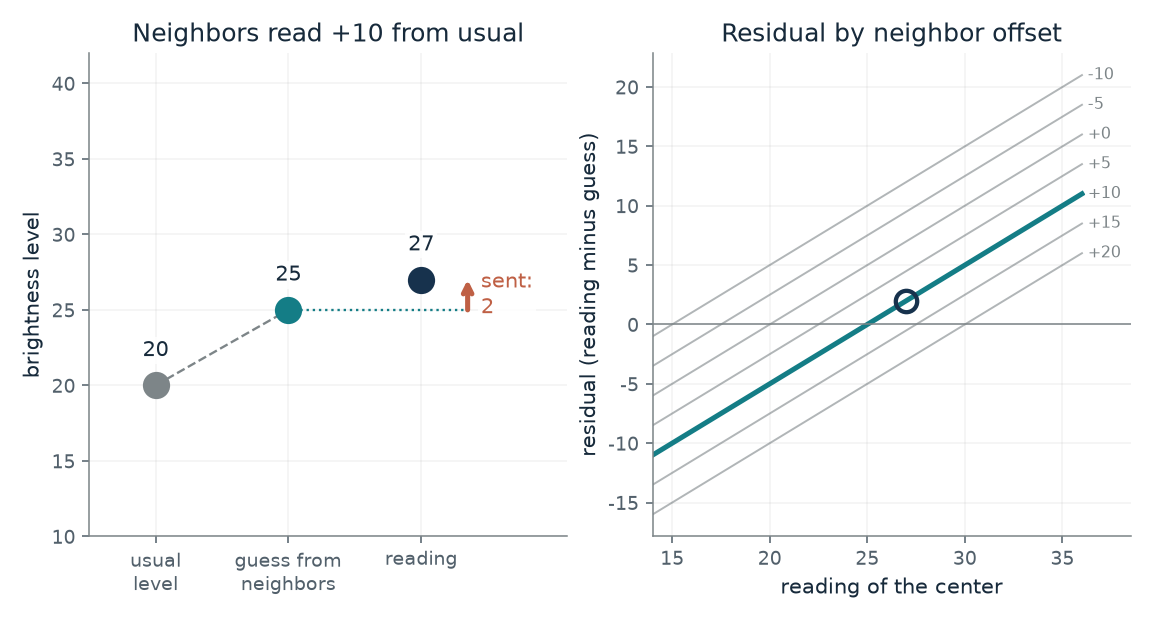

- **Guess:** 25
- **Residual sent:** 2
- **Reading minus usual:** 7
- **Size saved:** 5

The neighbors read +10 from their usual level, so the guess is 20 + 0.5 x 10 = 25. A reading of 27 leaves a residual of 2, which the receiver adds back to the guess to recover 27.

Guess = 20 + 0.5 x 10 = 25. Residual = 27 - 25 = 2. Receiver: 25 + 2 = 27.

In [2]:
figure, values, explanation = residual_picture(**{'neighbour_offset': 10, 'reading': 27})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much does a shared guess leave to send?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Neighbors' reading above or below usual = 10, Center reading = 22: The guess is 25. A reading of 22 leaves a residual of -3 and a reading of 27 leaves 2. Try a neighbor offset of -10 with a reading of 27: the guess is 15 and the residual is 12, larger than the 7 the reading sits above its usual level, so a bad guess costs more than none.

**Takeaway:** When sender and receiver share a guess, only the residual needs sending, and it is small whenever the guess is close.

**Why it matters:** A cell or a code has only so many signal levels to spend. If neighbors have already said most of what the center will say, the whole range can go to the small difference left over.

**In brains and behavior:** Srinivasan, Laughlin and Dubs proposed in 1982 that a cell's surround is a weighted average of neighboring receptors, used as a guess that the cell subtracts from its center signal. The mechanism is a proposal.

**In machines:** A machine can fit the same guess from data with no cell involved and send only the residual; the saving depends on the guess and the required precision.

**Where it applies:** The sender and receiver both know the center's usual level, the fraction and the neighbors' reading. Any saving depends on how good the guess is and how precisely the reading must be sent.

**Check your understanding:** In a three-level network, a long bar has input 10 and a prediction of 10, and a short bar has input 10 and a prediction of 4. What residual does each send?

<details><summary>Show the answer</summary>

The long bar sends 10 - 10 = 0 and the short bar sends 10 - 4 = 6. A well-predicted input leaves little to carry.

</details>

*Source: Chapter 4, Sending only what the guess missed. The chapter's constructed numbers: usual level 20, a fraction of one half, neighbors 10 above their usual level, a guess of 25, and readings of 27 and 22 giving residuals 2 and -3. The chapter calls this the textbook form of the idea, not an equation quoted from Srinivasan, Laughlin and Dubs.*

## C04-D02: How does a machine fit the guess, and how much does it save?

If a machine counts how a center and its neighbors moved together over many examples, what guess does it fit and how much of the spread is left in the residuals?

If the center rises when the neighbors rise, a bright neighborhood lifts the guess. If the neighbors tell nothing, the guess falls back to the usual brightness and the whole reading must be sent. In between, the guess removes a share rho^2 of the variance and leaves 1 - rho^2.

$$
\hat c=\bar c+\frac{\mathrm{Cov}(c,f)}{\mathrm{Var}(f)}(f-\bar f),\qquad \frac{\mathrm{SD}(e)}{\mathrm{SD}(c)}=\sqrt{1-\rho^{2}}
$$

**Symbols:** Cov(c, f): how much the center and neighbors rise and fall together; Var(f): how widely the neighbors swing; it must be above zero; rho: correlation between center and neighbors, from -1 to 1; SD(e) / SD(c): spread of the residual compared with the spread of the raw reading

**Predict before looking:** If the center follows its neighbors with correlation 0.8, predict what share of the raw spread is left in the residuals.

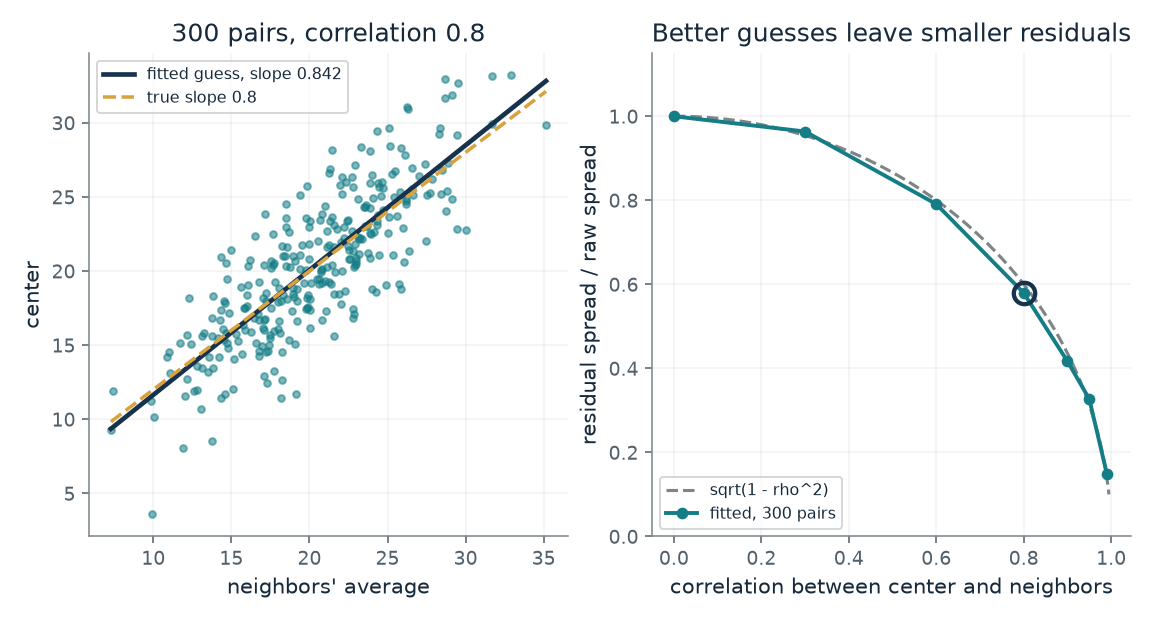

- **Fitted slope:** 0.842
- **Residual spread / raw spread:** 0.579
- **Theory sqrt(1 - rho^2):** 0.6
- **Bits saved at equal precision:** 0.788

Fitted from 300 pairs, the guess has slope 0.842 against a true 0.8, and its residuals have 0.579 of the raw spread (theory 0.6). Sending the residual at the same precision then saves about 0.788 bits per reading; this bit count is the companion's addition.

Slope = Cov(c, f) / Var(f) = 0.842. Residual spread / raw spread = 0.579; sqrt(1 - 0.8^2) = 0.6. Bits saved = log2(1 / 0.579) = 0.788.

In [3]:
figure, values, explanation = fitted_guess_picture(**{'rho': 0.8, 'n': 300})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a machine fit the guess, and how much does it save?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Correlation between center and neighbors = 0.8, Number of example pairs = 3000: With 3,000 pairs the fitted slope is 0.816 and the residuals keep 0.603 of the raw spread, close to the theory 0.6. With 30 pairs the slope is 0.878 and the share 0.564: a short record gives a rougher guess.

**Takeaway:** The best straight-line guess leaves a residual whose spread is sqrt(1 - rho^2) of the raw spread, so the better the neighbors predict the center, the less there is to send.

**Why it matters:** A machine can fit this guess from examples and use it as a simple baseline before adding complexity. How much it saves depends on the correlation and on how precisely the reading must be sent.

**In brains and behavior:** The theory of Srinivasan and colleagues asks what a cell's surround would have to be if it were such a guess. Nothing here shows how cells would learn it.

**In machines:** Fitting the slope Cov / Var from examples is ordinary least squares, a specification, and it needs the neighbors to vary.

**Where it applies:** A straight-line guess under squared error, normally distributed pairs, residuals scored on the same pairs the line was fitted to, and equal precision for the raw reading and the residual when counting bits. Association alone does not show that changing the neighbors would change the center.

**Check your understanding:** The center and its neighbors have correlation 0.6. What share of the center's spread remains in the residual?

<details><summary>Show the answer</summary>

sqrt(1 - 0.36) = sqrt(0.64) = 0.8, so the residual keeps 0.8 of the raw spread.

</details>

*Source: Chapter 4, A fly's ring against a fitted guess. The book's formula and its derivation 5. The pairs are a seeded simulation (seed 4) with mean 20, spread 5 and a chosen correlation; seed 4 was picked after trying a few because its fits were typical, and with 30 pairs fits scatter more whatever the seed. The ratio sqrt(1 - rho^2) and the bit count are standard results added by the companion and not printed in the chapter.*

## C04-D03: Why would a surround weaken and spread in dim light?

If each receptor's reading is noisier, how should a guess weigh its neighbors?

With no noise, a nearer neighbor tells everything a farther one could, so only the nearest two get weight. Noise makes each neighbor a poorer witness, so each is trusted less, and several noisy witnesses together beat one. The guess falls back toward the usual level when all of them are noisy.

$$
\mathbf w=(K+vI)^{-1}\mathbf k,\qquad K_{ij}=e^{-|d_i-d_j|/L},\quad k_i=e^{-|d_i|/L}
$$

**Symbols:** w: weights on the eight neighbors in the guess for the center; v: noise variance of each receptor, as a multiple of the signal variance; dimmer light is larger; L: how far a scene stays alike, in spots (made up); d_i: distance of neighbor i from the center, in spots, from -4 to 4

**Predict before looking:** As the noise variance rises from 0 to 10, predict whether the total weight on the neighbors rises or falls, and whether the nearest two neighbors' share of it rises or falls.

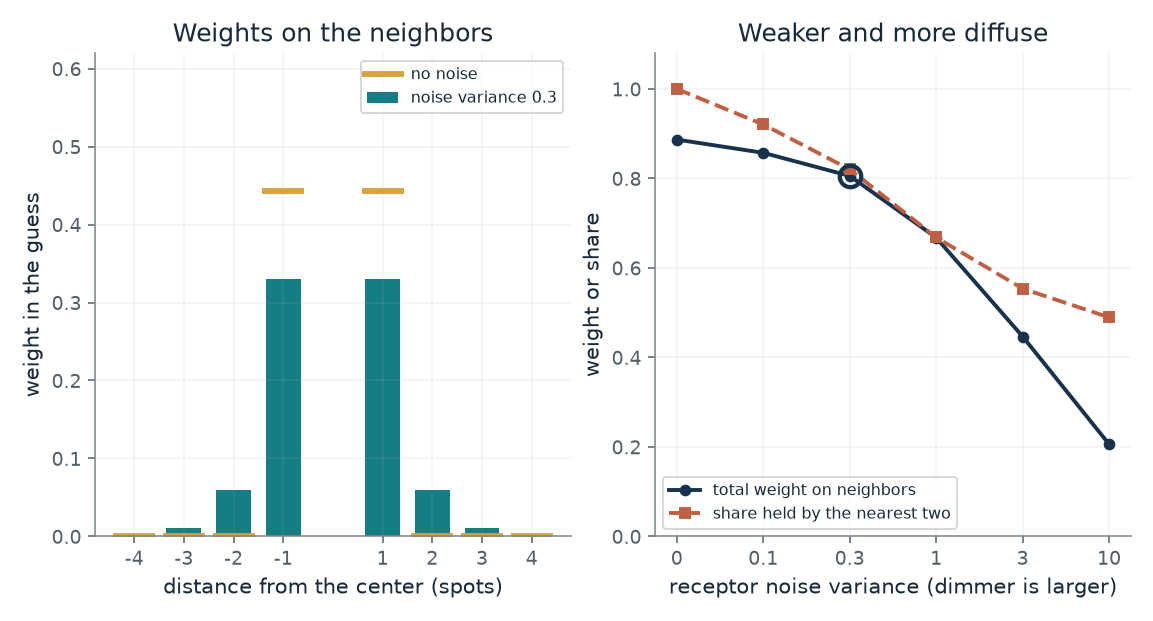

- **Total weight:** 0.806
- **Share on the nearest two:** 0.82
- **Residual share of the reading's variance:** 0.654
- **Total weight with no noise:** 0.887

At noise variance 0.3 the guess puts total weight 0.806 on the neighbors, down from 0.887 with no noise, and the nearest two hold 0.82 of it. Noisier neighbors earn less weight each, and averaging over more of them helps smooth the noise.

Weights w solve (K + v I) w = k, with K_ij = exp(-|d_i - d_j| / L) between neighbors, k_i = exp(-|d_i| / L) between neighbor and center, v the noise variance and L the correlation length.

In [4]:
figure, values, explanation = surround_picture(**{'noise_variance': 0.3, 'corr_length': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why would a surround weaken and spread in dim light?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Receptor noise variance (dimmer is larger) = 3, How far the scene stays alike (spots) = 2: At noise variance 3 the total weight on the neighbors falls from 0.887 to 0.447, and the nearest two hold 0.554 of it instead of all of it. The surround is weaker and more spread out, the direction the theory predicted.

**Takeaway:** Noisier neighbors earn less weight each, and the weight spreads over more of them, because averaging more neighbors smooths out random noise.

**Why it matters:** A guess is only as good as the readings behind it. A system that knows its inputs are noisier should lean on them less and pool over more of them.

**In brains and behavior:** The theory made a prediction that could fail: the surround should grow weaker and more diffuse in dim light. It was reported to hold, with the measured surrounds more diffuse than predicted.

**In machines:** A smoother or filter that is told its inputs are noisier shrinks its weights and widens its window; this is the same arithmetic as a regularized straight-line fit.

**Where it applies:** A one-dimensional row of spots with unit signal variance, independent receptor noise, and the best straight-line guess under squared error. The chapter calls the predictive mechanism a proposal, and nothing here is a fit to the fly's data.

**Check your understanding:** With no noise and the correlation between adjacent spots equal to r = e^(-1/2) = 0.6065 (L = 2), what weight does each nearest neighbor get?

<details><summary>Show the answer</summary>

Two flanking neighbors with correlation r to the center and r^2 to each other give w = r / (1 + r^2) = 0.6065 / 1.3679 = 0.443 each, and all farther neighbors get weight 0.

</details>

*Source: Chapter 4, A fly's ring against a fitted guess. Companion calculation of the theory's qualitative prediction. The chapter gives no weights; the row of eight neighbors, the exponential fall of similarity with distance and the noise values are made up. Srinivasan, Laughlin and Dubs reported that the weakening and widening was demonstrated in large monopolar cells of the fly Lucilia cuprina, though at the two light levels tested the measured surrounds were more diffuse than the theory predicted.*

## C04-D04: Where does an estimate settle between the input and the expectation?

If the input says 12 and the expectation from above says 2, where should the estimate land when one source is less reliable?

The input pulls the estimate toward itself and so does the expectation. Each pull is its gap times its reliability, and the estimate stops where the two pulls are equal, so the more reliable source holds it closer.

$$
\tau_I\,(I-\hat r)=\tau_{\text{td}}\,(\hat r-r_{\text{td}}),\qquad \hat r=\frac{\tau_I I+\tau_{\text{td}} r_{\text{td}}}{\tau_I+\tau_{\text{td}}},\qquad \tau=\frac{1}{\text{variance}}
$$

**Symbols:** I: the input from below, 12 here; r_td: the expectation from above, 2 here; tau_I, tau_td: reliabilities, one divided by each source's noise variance; r-hat: the settled estimate, where the two pulls are equal

**Predict before looking:** Predict where the estimate settles when the input's noise variance is 1 and the expectation's is 10: near 7, near 12 or in between.

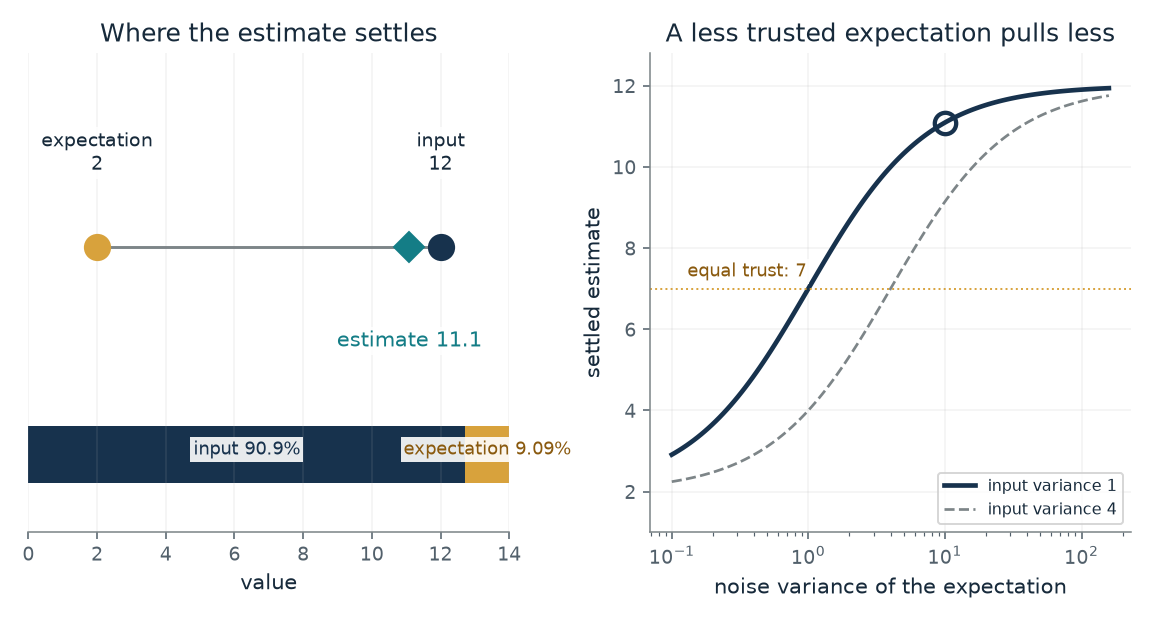

- **Settled estimate:** 11.1
- **Input's share:** 0.909
- **Input reliability:** 1
- **Expectation reliability:** 0.1

With noise variances 1 for the input and 10 for the expectation, the estimate settles at 11.1, between the expectation 2 and the input 12. The input's reliability is 10 times the expectation's, so it holds that share of the pull.

Reliabilities 1 and 0.1. Estimate = (1 x 12 + 0.1 x 2) / (1 + 0.1) = 11.1.

In [5]:
figure, values, explanation = settling_picture(**{'expect_variance': 10, 'input_variance': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Where does an estimate settle between the input and the expectation?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Noise variance of the expectation = 10, Noise variance of the input = 1: The estimate settles at 11.1, about 91 percent of the way from the expectation to the input. The expectation was set to be trusted little, so the input holds most of the pull; at equal variances it would settle at 7.

**Takeaway:** The estimate stays closer to the source with the smaller noise variance, and a source with ten times the variance gets one tenth of the weight.

**Why it matters:** The same arithmetic as the precision-weighted blend of Chapter 2 shows up here between levels: a system that mixes what it sees with what it expects is only as good as the noise levels it is given.

**In brains and behavior:** The one brain hint is the fly's surround, reported to weaken in dim light. Nothing in Rao and Ballard's paper shows how neurons would represent how much to trust a source.

**In machines:** In the simulated network each level settles by this rule with noise variances the authors chose; it is a specification for the machine, not a measurement of cells.

**Where it applies:** One number at one level, a link between levels that passes the value through unchanged, positive noise variances and no prior term. The same 11.1 follows from a Bayesian calculation with a bell-shaped prior at 2 (variance 10) and reading error variance 1, but that does not turn this equation into the full model.

**Check your understanding:** Input 12, expectation 2, equal reliability: where does the estimate settle? And if the expectation's variance is 4 times the input's?

<details><summary>Show the answer</summary>

Equal reliability gives 7, halfway. With reliabilities 1 and 0.25 the estimate is (12 + 0.25 x 2) / 1.25 = 10.

</details>

*Source: Chapter 4, How far to trust the guess. The chapter's made-up readings: input 12 and expectation 2. Equal reliability settles at 7; the end-stopping run's variances (1 for the input, 10 for the expectation, chosen by Rao and Ballard) settle near 11.1. The chapter says this is the book's own arithmetic, a simplified one-number form of the paper's update with the prior term left out.*

## C04-D05: How far should a surprise move the next prediction?

A color usually wins, and today it lost. Should the prediction move a lot or a little, in a steady world and in one whose chances change?

A small rate averages over many outcomes, which cancels luck but follows a real shift slowly. A large rate follows a shift quickly but treats every unusual outcome as news. Which is better depends on how often the world really changes.

$$
\hat v_{t+1}=\hat v_t+\alpha\,(o_t-\hat v_t)
$$

**Symbols:** v-hat_t: the predicted chance that the color wins; o_t: the outcome, 1 for a win and 0 for a loss; alpha: the learning rate, the share of the prediction error used to change the prediction

**Predict before looking:** A steady world rewards a small learning rate. Predict whether the best rate on the list rises or falls when the win chance is redrawn with chance 0.02 on each trial.

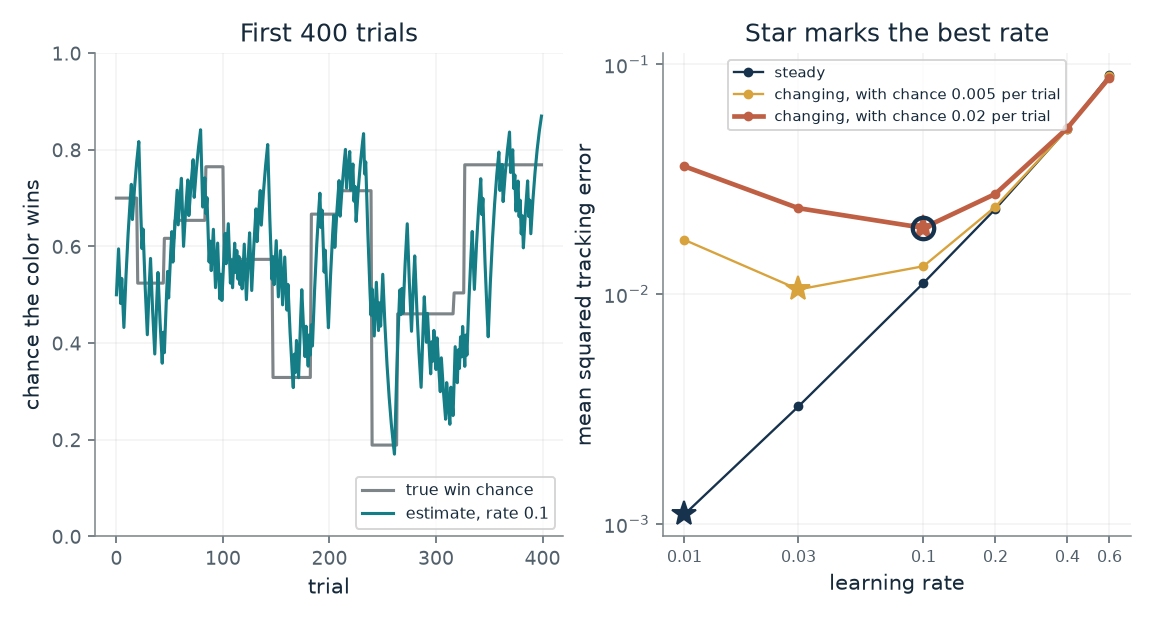

- **Tracking error:** 0.0194
- **Best rate here:** 0.1
- **Error at the best rate:** 0.0194
- **Rate chosen:** 0.1

In a world that is changing, with chance 0.02 per trial, a learning rate of 0.1 gives mean squared tracking error 0.0194, and the best rate on this list is 0.1. This is a seeded simulation with made-up chances, not Behrens and colleagues' data.

Update: estimate = estimate + rate x (outcome - estimate). 59,000 scored trials, seed 2026. For a steady chance p, the long-run error is p(1-p) x rate / (2 - rate).

In [6]:
figure, values, explanation = learning_rate_picture(**{'rate': 0.1, 'change_chance': 0.02})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How far should a surprise move the next prediction?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Learning rate = 0.1, Chance the win chance is redrawn per trial = 0.0: In the steady world, a rate of 0.1 gives error 0.0112, about ten times the 0.0011 of rate 0.01. In the world that changes with chance 0.02 per trial the ranking flips: 0.01 gives 0.036 and 0.1 gives 0.0194, the best on the list.

**Takeaway:** A larger share of each error is worth using only when the world really changes; in a steady world it mostly chases luck.

**Why it matters:** Surprises can come from an unusual outcome or from a changed world, and the right response differs. Volatility means how fast the underlying chances change, not how often outcomes surprise.

**In brains and behavior:** Behrens and colleagues fitted a learning model to people's color choices, and the estimated learning rate was higher in the changing part. Browning and colleagues found an association between an anxiety questionnaire score and a smaller difference between fitted rates in a shock task. These are associations summarizing choices under a model, not a direct measurement of a mechanism and not a rule for any individual.

**In machines:** A system that updates a forecast has to decide how much weight new errors get. A larger update follows a genuine shift sooner and a smaller one resists random fluctuation. The human experiments do not establish a best setting for a machine.

**Where it applies:** Independent outcomes with a win chance that is either fixed or occasionally redrawn at random, and a simple delta-rule learner whose error is scored against the true chance. The scored error for a steady chance p is p(1 - p) x alpha / (2 - alpha); the other curves are simulated.

**Check your understanding:** In a steady world with win chance 0.7, what long-run squared error does a learning rate of 0.2 give?

<details><summary>Show the answer</summary>

p(1 - p) x alpha / (2 - alpha) = 0.21 x 0.2 / 1.8 = 0.0233; the simulation gives 0.0235.

</details>

*Source: Chapter 4, A changing world calls for a different update. A seeded simulation (seed 2026, 60,000 trials) made by the companion. The chapter gives no numbers: the win chance of 0.7 in the steady world, the redrawing of the chance uniformly between 0.1 and 0.9 with a stated chance per trial, and the list of rates are made up. It is not Behrens and colleagues' data or task.*

## C04-D06: What happens when an expectation counts for too much?

If a percept leans on an expected tone, how often will a tone be reported when none was played?

With more weight on the expectation, the percept shifts toward the expected tone and the sensory sample matters less. On no-tone trials the percept's mean moves from 0 toward 1 and across the criterion, and on tone trials it moves from 1 only closer to 1 while its spread shrinks.

$$
\text{percept}=w\,s_{\text{exp}}+(1-w)\,x,\qquad x\sim\mathcal{N}(\mu,\sigma^{2}),\quad \mu=\begin{cases}1&\text{tone played}\\0&\text{no tone}\end{cases}
$$

**Symbols:** w: weight on the expectation, from 0 up to but not including 1; s_exp: the expected tone strength, 1; x, sigma: the sensory sample and its noise spread (made up); criterion: a tone is reported when the percept exceeds 0.5

**Predict before looking:** With sensory spread 0.5 and no weight on the expectation, a tone is reported on 84 percent of tone trials and 16 percent of no-tone trials. Predict both rates when the weight rises to 0.5.

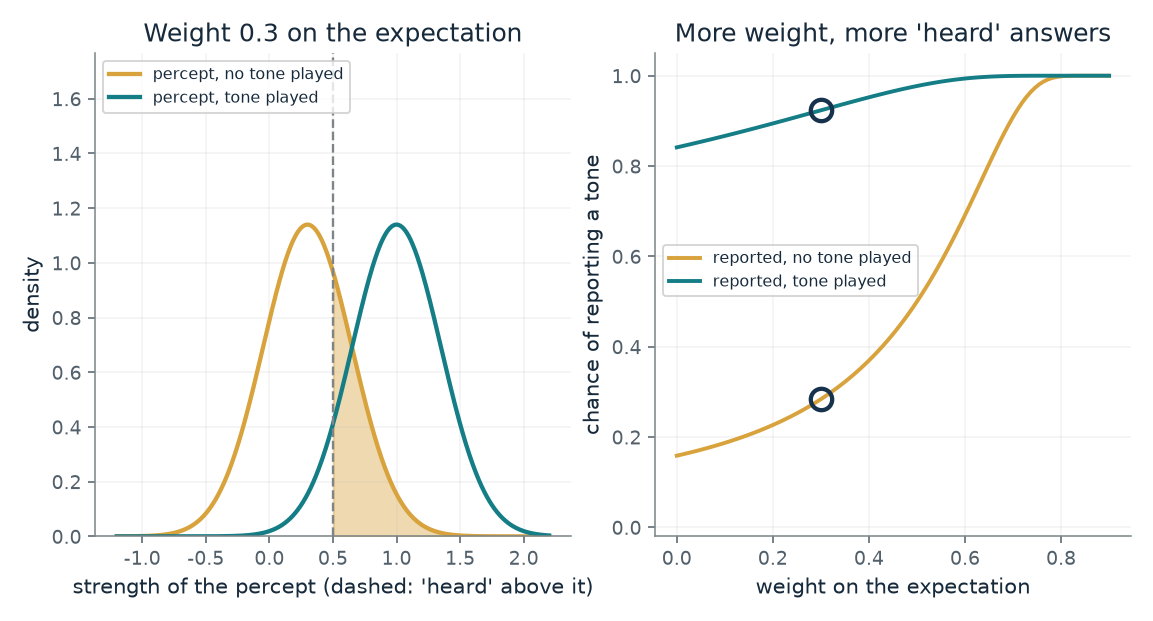

- **Reported when absent:** 0.284
- **Reported when present:** 0.923
- **Weight on the expectation:** 0.3
- **Sensory noise sd:** 0.5

With weight 0.3 on the expectation, a tone is reported on 28.4 percent of no-tone trials and 92.3 percent of tone trials. Giving the expectation more weight pulls the percept toward the tone, so 'heard' answers rise whether or not it played.

Percept = 0.3 x 1 + 0.7 x sample. No tone: sample mean 0, so percept mean 0.3, sd 0.35. P(percept > 0.5) = 0.284. Tone played: mean 1, P = 0.923.

In [7]:
figure, values, explanation = prior_weight_picture(**{'prior_weight': 0.3, 'sensory_sd': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What happens when an expectation counts for too much?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Weight on the expectation = 0.5, Sensory noise spread = 0.5: At weight 0.5, a tone is reported on 98 percent of tone trials and on 50 percent of no-tone trials, because the no-tone percept now centers on the criterion. Both rates rise: more weight on the expectation pulls every answer toward 'heard'.

**Takeaway:** A guess given more weight pulls the result toward itself, so reports of a tone rise whether or not one was played.

**Why it matters:** A prior helps make sense of an unclear signal, but a prior that counts for too much can supply what is not there. The same trade appears wherever a system mixes what it expects with what it receives.

**In brains and behavior:** In the tone task, all four groups reported some absent tones, and as groups the people who heard voices daily reported more, with or without a diagnosis. The fitted model gave their expectation more weight. In another task, people with early psychotic symptoms benefited more from seeing clear pictures first. These are group findings and model interpretations, not claims about any person, and the chapter notes evidence for weaker priors too.

**In machines:** A system that fuses a prior with a reading will report what it expects if the prior weight is too high; the weight is a design setting.

**Where it applies:** A weighted mix of the expectation and a noisy sensory sample and a fixed reporting criterion. The studies' own model is an interpretation of reports, not a direct measurement of a weight in the brain, and the human studies do not show that a brain uses Rao and Ballard's rule.

**Check your understanding:** At weight 0.5 and spread 0.5, the no-tone percept has mean 0.5, the same as the criterion. What share of no-tone trials are reported as 'heard'?

<details><summary>Show the answer</summary>

Half, 50 percent, because the percept is as likely to fall above the criterion as below it.

</details>

*Source: Chapter 4, When an expectation outweighs the senses. A constructed model by the companion in the spirit of the chapter's analogy to the balance between a reading and a guess. The chapter gives no weights or rates: the tone strength 1, the criterion 0.5 and the noise spreads are made up. Powers, Mathys and Corlett studied 59 people in four groups; this is not their model or data.*

## C04-D07: Is a surprise the same as something to learn?

If an agent is paid for its own prediction error, when does the payment stop?

Surprise averages the cost of each flip's outcome against the learner's prediction, and for a fair coin that cost never falls below 1 bit. Information gain measures how much seeing the flip sharpens the learner's view of the coin, and that shrinks as flips accumulate because the view is already sharp. An always-heads coin stops being a surprise because the learner stops being wrong.

$$
\text{surprise}=-\log_2 q,\qquad q=\frac{h+1}{n+2},\qquad \text{gain}=H_b(q)-\mathbb{E}_{\theta\mid h,n}\!\left[H_b(\theta)\right]
$$

**Symbols:** n, h: flips seen so far and how many were heads; q: the learner's predicted chance of heads for the next flip, from a uniform starting view; H_b: the binary entropy in bits, H_b(x) = -x log2 x - (1 - x) log2 (1 - x); theta: the coin's unknown chance of heads

**Predict before looking:** For the fair coin, predict whether the expected surprise after 100 flips is near 0, 0.5 or 1 bit, and whether the information gain is large or small.

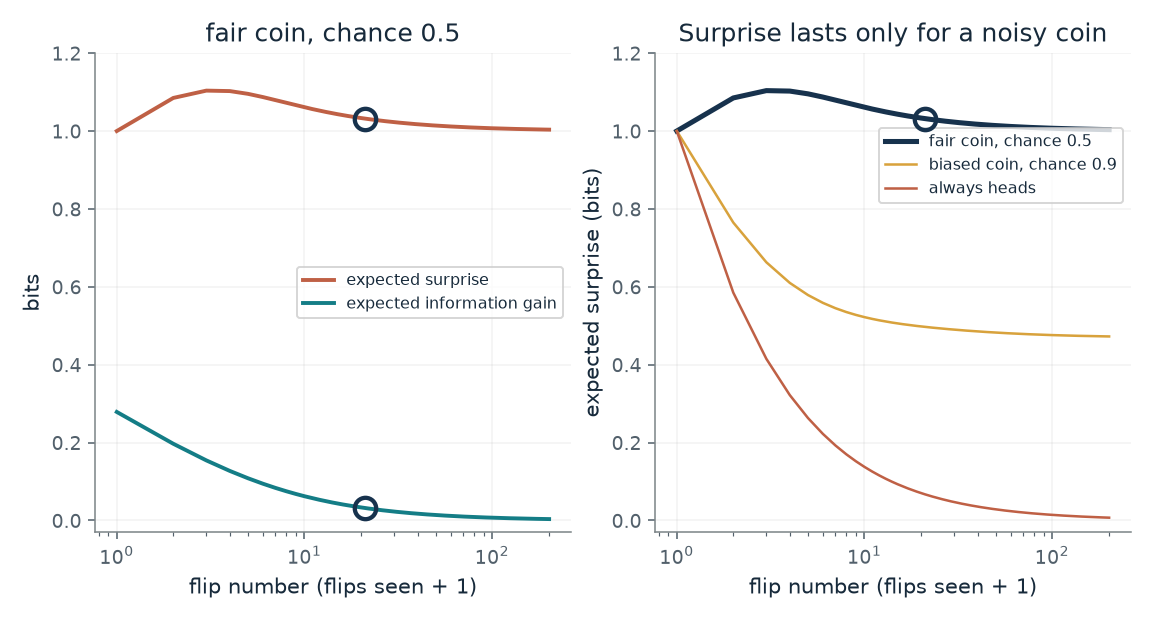

- **Expected surprise (bits):** 1.03
- **Expected information gain (bits):** 0.032
- **Flips seen:** 20
- **Surprise if the coin is known:** 1

After 20 flips of the fair coin, chance 0.5, the next flip is worth 1.03 bits of surprise but only 0.032 bits of information about the coin. An agent paid for surprise keeps being paid where the coin is fair; one paid for information gain is not.

Learner starts from a uniform view of the chance of heads; after h heads in n flips it predicts heads with (h + 1) / (n + 2). Surprise is -log2 of the predicted chance of the flip that occurs. Information gain is H(predicted flip) minus the expected H(flip given the coin's chance).

In [8]:
figure, values, explanation = surprise_picture(**{'coin_chance': 0.5, 'flips_seen': 20})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Is a surprise the same as something to learn?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Coin's chance of heads = 0.5, Flips seen so far = 100: After 100 flips of the fair coin the next flip is still worth 1.01 bits of surprise, but only 0.007 bits of information about the coin, close to 1 / (2 n ln 2). A reward for surprise keeps paying here; a reward for information gain has nearly stopped.

**Takeaway:** An agent paid for surprise keeps being paid by a coin that is fair, while one paid for information gain stops once the chance is learned.

**Why it matters:** A prediction error can mean the guess was wrong, or it can mean the world is only noisy. Being surprised is not the same as learning something, and a machine paid for surprise can keep paying itself for noise it cannot learn from.

**In brains and behavior:** No test in the chapter shows whether people or animals chase surprise or information.

**In machines:** Burda and colleagues (2018) rewarded agents with prediction error on features. Across 54 environments the curious agents often earned game score they were never trained on, and in one purpose-built maze a television that switched to a random channel drastically slowed learning. A reward for expected information gain is a design idea, not a result in that paper.

**Where it applies:** Independent flips of a coin with chance 0.5, 0.9 or 1 of heads, and a learner that starts from a uniform view of the coin. Expected surprise is the learner's log loss, a stand-in for prediction error. A learner that already knew the coin would have zero information gain at every flip.

**Check your understanding:** If the agent already knows the coin is fair, what is the expected information gain from the next flip, and what is the surprise?

<details><summary>Show the answer</summary>

Zero bits of information gain, since nothing about the coin is left to learn, and exactly 1 bit of surprise per flip.

</details>

*Source: Chapter 4, A television that changed channels. The chapter's coin paragraph: a known fair coin teaches nothing, a coin of uncertain fairness teaches, and a coin that always lands heads stops being a surprise. The companion's exact calculation adds a uniform starting view (Laplace's rule) and sums over the flips. It is not a simulation of Burda and colleagues' agents, who were paid for prediction error on learned features.*

## Bring it to your own question

Ask what the guess is, how reliable it has been compared with the new reading, and whether the world is steady or changing. Use the residual when a sender and receiver share a guess, the settling rule to weigh an expectation against an input, a learning-rate comparison when the question is how far to move a forecast, and the surprise-versus-information card before rewarding a system for prediction error. Remember that a large residual does not say why it is large.

Use the `mmi-ch04-expecting-world` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.